# Détection des maladies de la tomate par CNN : du laboratoire au terrain
Projet de fin de module Deep Learning (cohorte 3, AI hub) — Culture ciblée : **tomate** — Plateforme : Google Colab (GPU).

Contenu : Étape 2 (exploration, découpage, baseline MLP), Étape 3 (CNN from scratch), Étape 4 (test de robustesse), Étape 5 (analyse des erreurs et explicabilité).
L'Étape 1 (fiche d'impact) est un document séparé.

In [1]:
import os, random, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, recall_score
from sklearn.utils.class_weight import compute_class_weight
from IPython.display import display
warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
IMG, BATCH, AUTOTUNE = 128, 64, tf.data.AUTOTUNE
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# Téléchargement des données (équivalent de download_data.py ; ignoré si déjà téléchargées)
DATA = Path("data"); DATA.mkdir(exist_ok=True)

def run(cmd, cwd=None):
    subprocess.run(cmd, cwd=cwd, check=True)

pv_root = DATA / "PlantVillage-Dataset"
if not pv_root.exists():
    run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
         "https://github.com/spMohanty/PlantVillage-Dataset.git", str(pv_root)])
    run(["git", "sparse-checkout", "set", "--no-cone", "raw/color/Tomato___*"], cwd=pv_root)

pd_root = DATA / "PlantDoc-Dataset"
if not pd_root.exists():
    run(["git", "clone", "--depth", "1", "https://github.com/pratikkayal/PlantDoc-Dataset.git", str(pd_root)])
print("Données prêtes.")

Données prêtes.


## Étape 2 — Exploration des données et baseline
### 2.1 Chargement et classes
PlantVillage contient 10 classes de tomate, PlantDoc en contient 9 (pas de *Target Spot*). Pour comparer le laboratoire et le terrain, on garde les **9 classes communes**.
Les dossiers sont associés aux classes par mots-clés ; le tableau ci-dessous permet de vérifier l'association.

In [3]:
CLASSES = ["Bacterial_spot", "Early_blight", "Late_blight", "Leaf_Mold", "Septoria_leaf_spot",
           "Spider_mites", "Mosaic_virus", "Yellow_Leaf_Curl_Virus", "Healthy"]
N = len(CLASSES)
CLS2ID = {c: i for i, c in enumerate(CLASSES)}

def to_common(folder):
    n = folder.lower().replace("_", " ").replace("-", " ")
    if "target" in n:
        return None
    for key, cls in [("early", "Early_blight"), ("late", "Late_blight"), ("septoria", "Septoria_leaf_spot"),
                     ("bacterial", "Bacterial_spot"), ("mosaic", "Mosaic_virus"),
                     ("yellow", "Yellow_Leaf_Curl_Virus"), ("mold", "Leaf_Mold"),
                     ("mite", "Spider_mites"), ("healthy", "Healthy")]:
        if key in n:
            return cls
    return "Healthy" if n.strip() in ("tomato leaf", "tomato") else None

EXT = {".jpg", ".jpeg", ".png"}
rows, excluded = [], []

def add_folder(d, domaine):
    cls = to_common(d.name)
    if cls is None:
        excluded.append((domaine, d.name)); return
    for p in d.iterdir():
        if p.suffix.lower() in EXT:
            rows.append({"path": str(p), "domaine": domaine, "dossier": d.name, "label": cls})

for d in sorted((pv_root / "raw" / "color").glob("Tomato___*")):
    add_folder(d, "PlantVillage")
for split in ("train", "test"):
    for d in sorted((pd_root / split).iterdir()):
        if d.is_dir() and "tomato" in d.name.lower():
            add_folder(d, "PlantDoc")

df = pd.DataFrame(rows)
display(df.groupby(["domaine", "dossier", "label"]).size().rename("images").to_frame())
print("Dossiers exclus :", sorted(set(excluded)))

images
domaine      dossier                                       label                         
PlantDoc     Tomato Early blight leaf                      Early_blight                88
             Tomato Septoria leaf spot                     Septoria_leaf_spot         151
             Tomato leaf                                   Healthy                     63
             Tomato leaf bacterial spot                    Bacterial_spot             110
             Tomato leaf late blight                       Late_blight                111
             Tomato leaf mosaic virus                      Mosaic_virus                54
             Tomato leaf yellow virus                      Yellow_Leaf_Curl_Virus      76
             Tomato mold leaf                              Leaf_Mold                   91
             Tomato two spotted spider mites leaf          Spider_mites                 2
PlantVillage Tomato___Bacterial_spot                       Bacterial_spot            2127
             Tomato___Early_blight                         Early_blight              1000
             Tomato___Late_blight                          Late_blight               1909
             Tomato___Leaf_Mold                            Leaf_Mold                  952
             Tomato___Septoria_leaf_spot                   Septoria_leaf_spot        1771
             Tomato___Spider_mites Two-spotted_spider_mite Spider_mites              1676
             Tomato___Tomato_Yellow_Leaf_Curl_Virus        Yellow_Leaf_Curl_Virus    5357
             Tomato___Tomato_mosaic_virus                  Mosaic_virus               373
             Tomato___healthy                              Healthy                   1591

Dossiers exclus : [('PlantVillage', 'Tomato___Target_Spot')]


In [4]:
# Qualité : images illisibles et doublons exacts (md5) supprimés
def is_ok(p):
    try:
        with Image.open(p) as im:
            im.verify()
        return True
    except Exception:
        return False

n0 = len(df)
df = df[df.path.map(is_ok)].copy()
n1 = len(df)
df["md5"] = df.path.map(lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest())
df = df.drop_duplicates("md5").reset_index(drop=True)
df["y"] = df.label.map(CLS2ID)
print(f"Images : {n0} | illisibles supprimées : {n0 - n1} | doublons exacts supprimés : {n1 - len(df)} | conservées : {len(df)}")

Images : 17502 | illisibles supprimées : 0 | doublons exacts supprimés : 17 | conservées : 17485


### 2.2 Exploration : classes, déséquilibre, exemples, qualité

domaine,PlantDoc,PlantVillage
label,,
Bacterial_spot,109,2127
Early_blight,88,1000
Late_blight,111,1901
Leaf_Mold,91,952
Septoria_leaf_spot,150,1771
Spider_mites,2,1676
Mosaic_virus,54,373
Yellow_Leaf_Curl_Virus,75,5357
Healthy,63,1585


PlantDoc : 743 images, 9 classes, rapport max/min = 75.0
PlantVillage : 16742 images, 9 classes, rapport max/min = 14.4


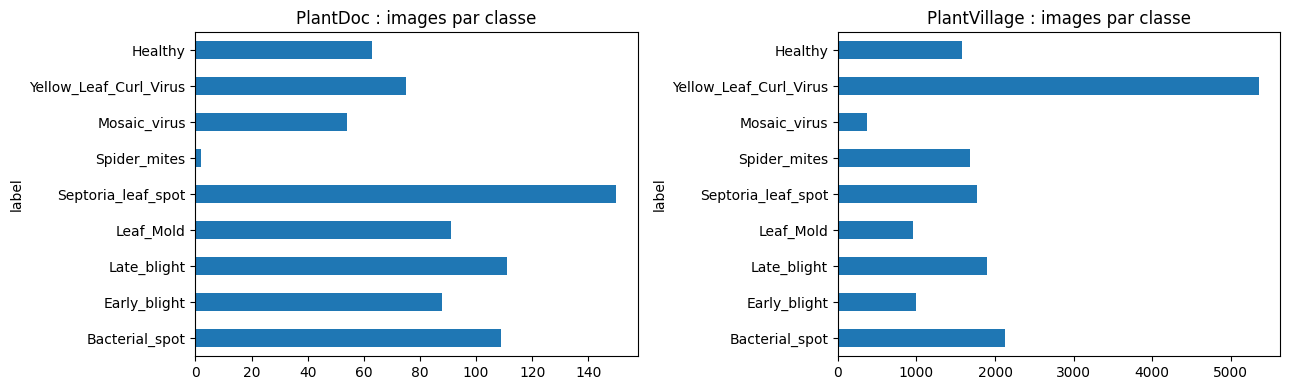

PlantDoc (échantillon de 200) : largeur min/médiane/max = 115/645/4416 | hauteur min/médiane/max = 85/580/3312
PlantVillage (échantillon de 200) : largeur min/médiane/max = 256/256/256 | hauteur min/médiane/max = 256/256/256


In [5]:
tab = pd.crosstab(df.label, df.domaine).reindex(CLASSES)
display(tab)
for dom in tab.columns:
    print(f"{dom} : {tab[dom].sum()} images, {N} classes, rapport max/min = {tab[dom].max() / tab[dom].min():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, dom in zip(ax, tab.columns):
    tab[dom].plot.barh(ax=a, title=f"{dom} : images par classe")
plt.tight_layout(); plt.show()

for dom in tab.columns:
    sample = df[df.domaine == dom].sample(min(200, (df.domaine == dom).sum()), random_state=SEED)
    sizes = np.array([Image.open(p).size for p in sample.path])
    print(f"{dom} (échantillon de {len(sample)}) : largeur min/médiane/max = "
          f"{sizes[:,0].min()}/{int(np.median(sizes[:,0]))}/{sizes[:,0].max()} | "
          f"hauteur min/médiane/max = {sizes[:,1].min()}/{int(np.median(sizes[:,1]))}/{sizes[:,1].max()}")

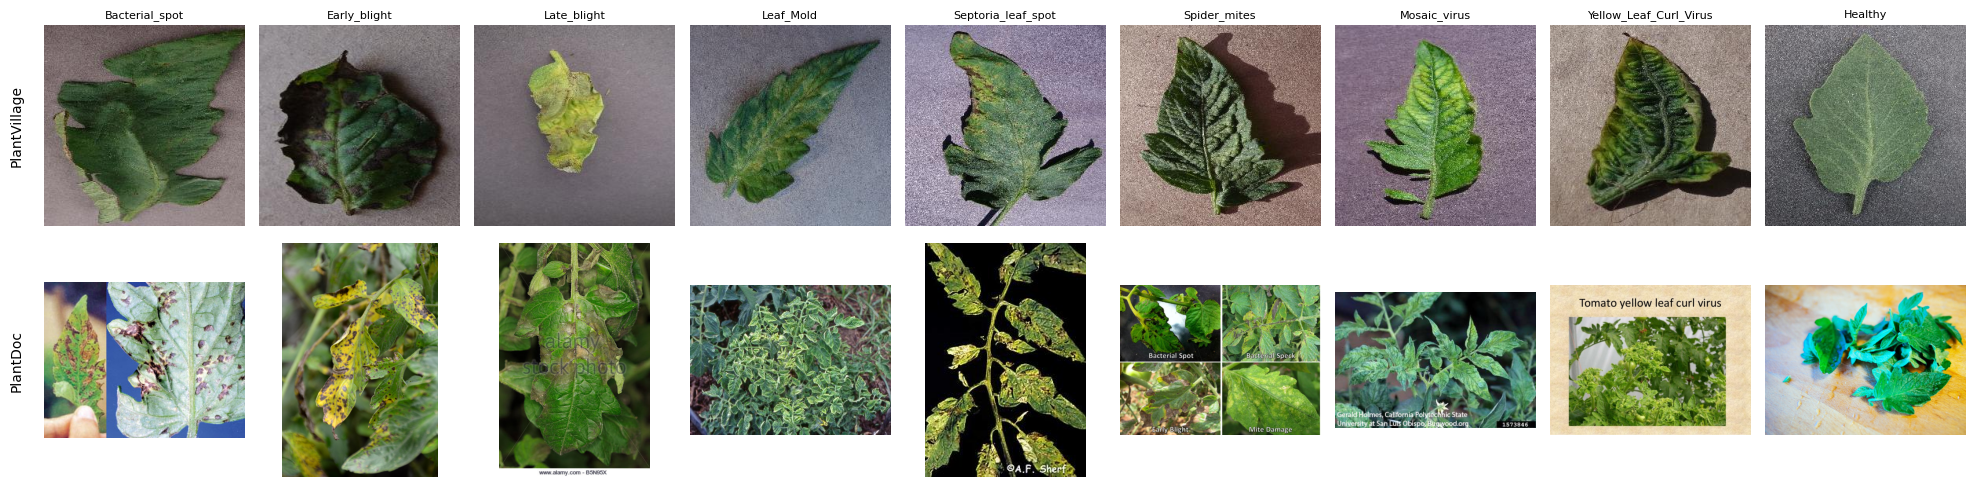

In [6]:
# Exemples d'images : une par classe, laboratoire (haut) et terrain (bas)
fig, axes = plt.subplots(2, N, figsize=(2.2 * N, 5))
for r, dom in enumerate(["PlantVillage", "PlantDoc"]):
    for c, cls in enumerate(CLASSES):
        sub = df[(df.domaine == dom) & (df.label == cls)]
        ax = axes[r, c]; ax.axis("off")
        if len(sub):
            ax.imshow(Image.open(sub.sample(1, random_state=SEED).path.iloc[0]).convert("RGB"))
        if r == 0:
            ax.set_title(cls, fontsize=8)
    axes[r, 0].text(-0.1, 0.5, dom, rotation=90, transform=axes[r, 0].transAxes, va="center", ha="right")
plt.tight_layout(); plt.show()

### 2.3 Découpage train / validation / test sans fuite de données
- Doublons exacts supprimés avant le découpage (voir 2.1) ;
- découpage stratifié **avant** toute augmentation ;
- le test n'est jamais utilisé pour entraîner ni pour choisir un modèle (le choix se fait sur la validation) ;
- vérification automatique qu'aucune image (md5) n'apparaît dans deux ensembles.

PlantVillage : 70 % train / 15 % val / 15 % test. PlantDoc : environ 56 % train / 19 % val / 25 % test.

In [7]:
pv_df, pd_df = df[df.domaine == "PlantVillage"], df[df.domaine == "PlantDoc"]

pv_tv, pv_test = train_test_split(pv_df, test_size=0.15, stratify=pv_df.y, random_state=SEED)
pv_train, pv_val = train_test_split(pv_tv, test_size=0.15 / 0.85, stratify=pv_tv.y, random_state=SEED)
pd_tv, pd_test = train_test_split(pd_df, test_size=0.25, stratify=pd_df.y, random_state=SEED)
pd_train, pd_val = train_test_split(pd_tv, test_size=0.25, stratify=pd_tv.y, random_state=SEED)

splits = {"PV train": pv_train, "PV val": pv_val, "PV test": pv_test,
          "PD train": pd_train, "PD val": pd_val, "PD test": pd_test}
hashes = [set(s.md5) for s in splits.values()]
assert sum(len(h) for h in hashes) == len(set().union(*hashes)), "Fuite : image présente dans 2 ensembles"
print({k: len(v) for k, v in splits.items()}, "| aucune fuite détectée")

{'PV train': 11718, 'PV val': 2512, 'PV test': 2512, 'PD train': 417, 'PD val': 140, 'PD test': 186} | aucune fuite détectée


In [8]:
# Pipeline de données (images en [0, 1], taille IMG x IMG)
def _load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG, IMG), antialias=True)
    img = tf.cast(tf.round(img), tf.uint8)
    img.set_shape((IMG, IMG, 3))
    return img, y

def random_background(img, p=0.7):
    # Changement de fond : la couleur de fond est estimée sur les bords, la feuille est isolée
    # par distance de couleur, puis le fond est remplacé par une couleur/texture aléatoire.
    border = tf.concat([tf.reshape(img[:6], [-1, 3]), tf.reshape(img[-6:], [-1, 3]),
                        tf.reshape(img[:, :6], [-1, 3]), tf.reshape(img[:, -6:], [-1, 3])], 0)
    bg = tf.reduce_mean(border, 0)
    dist = tf.norm(img - bg, axis=-1, keepdims=True)
    mask = tf.cast(dist > 0.12, tf.float32)
    mask = tf.nn.avg_pool2d(mask[None], 5, 1, "SAME")[0]
    texture = tf.image.resize(tf.random.uniform([8, 8, 3]), (IMG, IMG))
    new_bg = 0.5 * tf.random.uniform([1, 1, 3]) + 0.5 * texture
    out = img * mask + new_bg * (1.0 - mask)
    return tf.cond(tf.random.uniform([]) < p, lambda: out, lambda: img)

def make_ds(d, training=False, bg=False):
    ds = tf.data.Dataset.from_tensor_slices((d.path.values.astype(str), d.y.values.astype("int32")))
    ds = ds.map(_load, num_parallel_calls=AUTOTUNE).cache()
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(2048, seed=SEED)
        if bg:
            ds = ds.map(lambda x, y: (random_background(x), y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

def cw(y):
    w = compute_class_weight("balanced", classes=np.arange(N), y=np.asarray(y))
    return dict(enumerate(w))

ds_pv_train, ds_pv_val, ds_pv_test = make_ds(pv_train, True), make_ds(pv_val), make_ds(pv_test)
ds_pd_train, ds_pd_val, ds_pd_test = make_ds(pd_train, True), make_ds(pd_val), make_ds(pd_test)
cw_pv = cw(pv_train.y)   # compense le déséquilibre des classes

### Métrique principale
L'accuracy seule n'est **pas** utilisée pour conclure. La métrique principale est le **rappel macro** (moyenne des rappels par classe) :
une maladie non détectée coûte plus cher (perte de récolte) qu'une fausse alerte (traitement inutile), et la moyenne par classe empêche les classes rares de passer inaperçues.
La **précision** (liée aux fausses alertes) et le **F1** sont rapportés par classe en complément, systématiquement sur les données de laboratoire (PlantVillage test) **et** de terrain (PlantDoc test).

In [9]:
def predict(model, d, ds):
    p = model.predict(ds, verbose=0)
    return d.y.values, p.argmax(1), p

def macro_recall(model, d, ds):
    y, yp, _ = predict(model, d, ds)
    return recall_score(y, yp, average="macro", labels=range(N), zero_division=0)

RESULTS = {}
def evaluate(name, model, show=True):
    row = {}
    for dom, d, ds in [("Labo", pv_test, ds_pv_test), ("Terrain", pd_test, ds_pd_test)]:
        y, yp, _ = predict(model, d, ds)
        p, r, f, _ = precision_recall_fscore_support(y, yp, labels=range(N), zero_division=0)
        row[f"{dom} rappel macro"], row[f"{dom} F1 macro"] = r.mean(), f.mean()
        if show:
            print(f"\n{name} — {dom} (test)")
            display(pd.DataFrame({"précision": p, "rappel": r, "F1": f}, index=CLASSES).round(3))
    RESULTS[name] = row
    return row

def train(model, train_ds, val_ds, class_weight=None, epochs=25, lr=1e-3, patience=4):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, class_weight=class_weight,
                  callbacks=[es], verbose=2)
    return h.history

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title(f"{title} : loss")
    ax[1].plot(h["accuracy"], label="train"); ax[1].plot(h["val_accuracy"], label="val"); ax[1].set_title(f"{title} : accuracy")
    for a in ax:
        a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()

def augmentation_block():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.15, fill_mode="reflect"),            # rotations
        layers.RandomZoom(0.2, fill_mode="reflect"),                 # recadrage
        layers.RandomBrightness(0.25, value_range=(0, 1)),           # luminosité
        layers.RandomContrast(0.25),
    ], name="augment")

def build_mlp(n):
    inp = keras.Input((IMG, IMG, 3))
    x = layers.Resizing(48, 48)(inp)
    x = layers.Flatten()(x)                                          # images aplaties
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    return keras.Model(inp, layers.Dense(n, activation="softmax")(x), name="mlp")

def build_cnn(n=N, depth=3, bn=True, aug=False):
    inp = keras.Input((IMG, IMG, 3)); x = inp
    if aug:
        x = augmentation_block()(x)
    for i in range(depth):
        x = layers.Conv2D(32 * 2 ** i, 3, padding="same", use_bias=not bn, name=f"conv{i}")(x)
        if bn:
            x = layers.BatchNormalization(name=f"bn{i}")(x)
        x = layers.Activation("relu", name="last_conv" if i == depth - 1 else f"act{i}")(x)
        x = layers.MaxPooling2D(name=f"pool{i}")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    return keras.Model(inp, layers.Dense(n, activation="softmax", name="head")(x),
                       name=f"cnn_d{depth}_{'bn' if bn else 'nobn'}")

def copy_weights(src, dst):
    names = {l.name for l in src.layers}
    for l in dst.layers:
        if l.weights and l.name in names and l.name != "augment":
            l.set_weights(src.get_layer(l.name).get_weights())

### 2.4 Baseline : MLP sur images aplaties
Rôle : justifier la nécessité du CNN. Les images sont redimensionnées en 48x48 puis aplaties.

Epoch 1/30
184/184 - 36s - 198ms/step - accuracy: 0.2844 - loss: 2.1823 - val_accuracy: 0.5486 - val_loss: 1.5324
Epoch 2/30
184/184 - 9s - 48ms/step - accuracy: 0.4229 - loss: 1.7160 - val_accuracy: 0.4701 - val_loss: 1.5103
Epoch 3/30
184/184 - 4s - 22ms/step - accuracy: 0.4311 - loss: 1.6529 - val_accuracy: 0.5717 - val_loss: 1.3733
Epoch 4/30
184/184 - 2s - 12ms/step - accuracy: 0.4560 - loss: 1.5613 - val_accuracy: 0.6059 - val_loss: 1.2312
Epoch 5/30
184/184 - 2s - 13ms/step - accuracy: 0.4657 - loss: 1.5157 - val_accuracy: 0.5772 - val_loss: 1.3021
Epoch 6/30
184/184 - 2s - 14ms/step - accuracy: 0.4645 - loss: 1.5395 - val_accuracy: 0.5876 - val_loss: 1.3110
Epoch 7/30
184/184 - 4s - 19ms/step - accuracy: 0.4834 - loss: 1.4779 - val_accuracy: 0.6178 - val_loss: 1.1694
Epoch 8/30
184/184 - 2s - 13ms/step - accuracy: 0.4823 - loss: 1.4896 - val_accuracy: 0.5991 - val_loss: 1.1226
Epoch 9/30
184/184 - 3s - 14ms/step - accuracy: 0.4859 - loss: 1.4708 - val_accuracy: 0.6461 - val_los

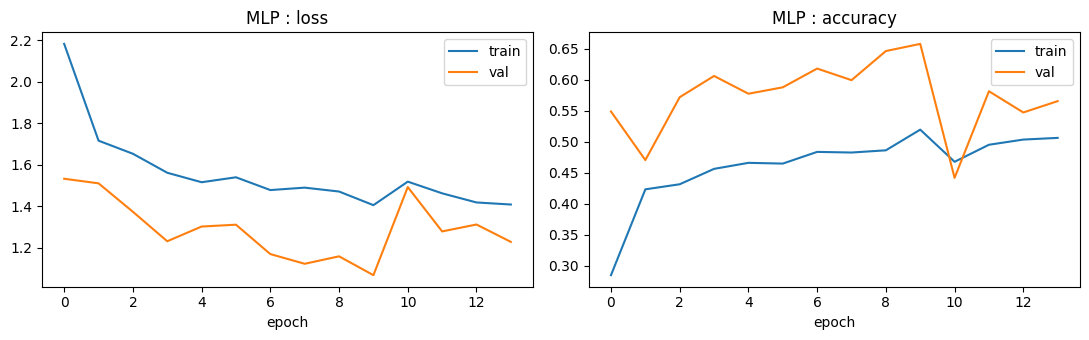


MLP (baseline) — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.523,0.771,0.624
Early_blight,0.292,0.313,0.302
Late_blight,0.673,0.382,0.488
Leaf_Mold,0.634,0.580,0.606
Septoria_leaf_spot,0.571,0.226,0.323
Spider_mites,0.683,0.661,0.672
Mosaic_virus,0.390,0.946,0.552
Yellow_Leaf_Curl_Virus,0.841,0.878,0.859
Healthy,0.732,0.815,0.771



MLP (baseline) — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.111,0.185,0.139
Early_blight,0.000,0.000,0.000
Late_blight,0.163,0.500,0.246
Leaf_Mold,0.000,0.000,0.000
Septoria_leaf_spot,0.000,0.000,0.000
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.000,0.000,0.000
Yellow_Leaf_Curl_Virus,0.045,0.053,0.049
Healthy,0.118,0.125,0.121


{'Labo rappel macro': np.float64(0.6193279438605269),
 'Labo F1 macro': np.float64(0.5775259620875548),
 'Terrain rappel macro': np.float64(0.0958685293480615),
 'Terrain F1 macro': np.float64(0.061610614777067495)}

In [10]:
keras.utils.set_random_seed(SEED)
mlp = build_mlp(N)
h_mlp = train(mlp, ds_pv_train, ds_pv_val, cw_pv, epochs=30)
plot_history(h_mlp, "MLP")
evaluate("MLP (baseline)", mlp)

## Étape 3 — CNN conçu from scratch
Architecture : blocs [Conv 3x3 → (BatchNorm) → ReLU → MaxPooling], puis GlobalAveragePooling, Dropout (0,4) et couche softmax.
Trois variantes comparées : **A** (3 blocs + BatchNorm), **B** (3 blocs sans BatchNorm → effet de la BN), **C** (4 blocs + BatchNorm → effet de la profondeur).
Entraînement sur PlantVillage (train), arrêt anticipé sur la loss de validation, poids de classes pour le déséquilibre.

In [11]:
CONFIGS = {"CNN-A (3 blocs + BN)": dict(depth=3, bn=True),
           "CNN-B (3 blocs, sans BN)": dict(depth=3, bn=False),
           "CNN-C (4 blocs + BN)": dict(depth=4, bn=True)}
cnn, hist = {}, {}
for name, cfg in CONFIGS.items():
    print(f"\n===== {name} =====")
    keras.utils.set_random_seed(SEED)
    m = build_cnn(**cfg)
    hist[name] = train(m, ds_pv_train, ds_pv_val, cw_pv, epochs=25)
    cnn[name] = m


===== CNN-A (3 blocs + BN) =====
Epoch 1/25
184/184 - 33s - 182ms/step - accuracy: 0.6344 - loss: 1.1032 - val_accuracy: 0.1270 - val_loss: 4.6463
Epoch 2/25
184/184 - 9s - 47ms/step - accuracy: 0.7706 - loss: 0.7113 - val_accuracy: 0.1290 - val_loss: 5.6200
Epoch 3/25
184/184 - 9s - 49ms/step - accuracy: 0.8070 - loss: 0.5832 - val_accuracy: 0.2775 - val_loss: 2.8778
Epoch 4/25
184/184 - 9s - 46ms/step - accuracy: 0.8327 - loss: 0.5160 - val_accuracy: 0.8081 - val_loss: 0.5786
Epoch 5/25
184/184 - 9s - 48ms/step - accuracy: 0.8426 - loss: 0.4670 - val_accuracy: 0.7341 - val_loss: 0.7771
Epoch 6/25
184/184 - 9s - 48ms/step - accuracy: 0.8629 - loss: 0.4216 - val_accuracy: 0.6385 - val_loss: 1.0380
Epoch 7/25
184/184 - 9s - 48ms/step - accuracy: 0.8725 - loss: 0.3867 - val_accuracy: 0.8049 - val_loss: 0.5684
Epoch 8/25
184/184 - 9s - 48ms/step - accuracy: 0.8828 - loss: 0.3471 - val_accuracy: 0.8611 - val_loss: 0.4097
Epoch 9/25
184/184 - 9s - 48ms/step - accuracy: 0.8926 - loss: 0.326

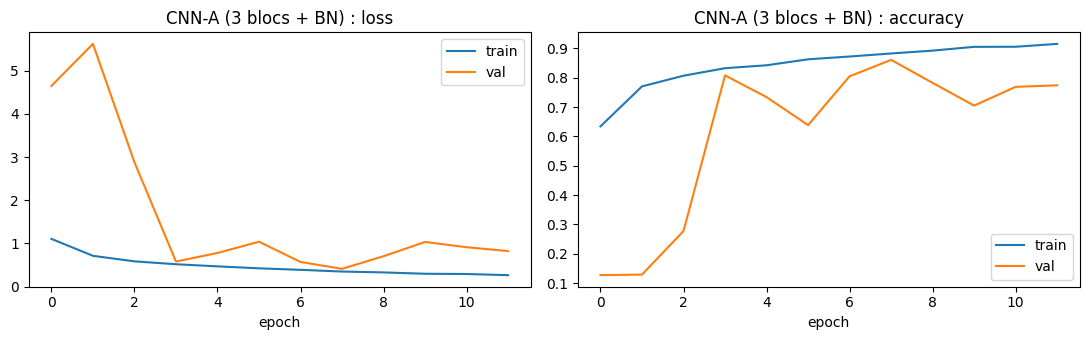

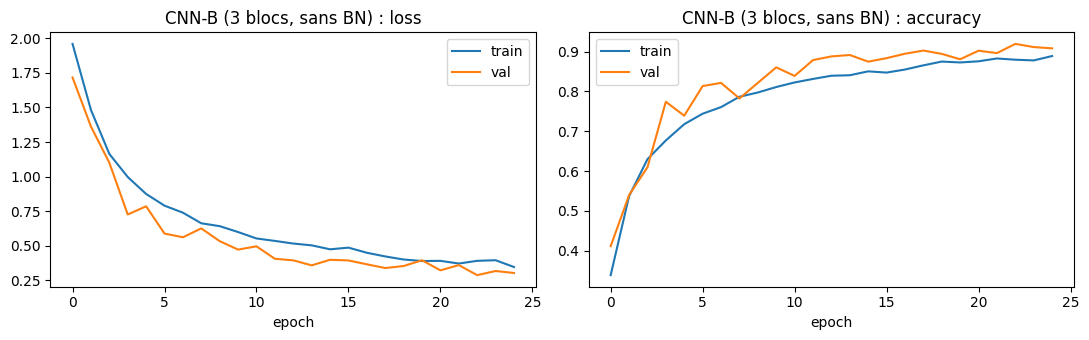

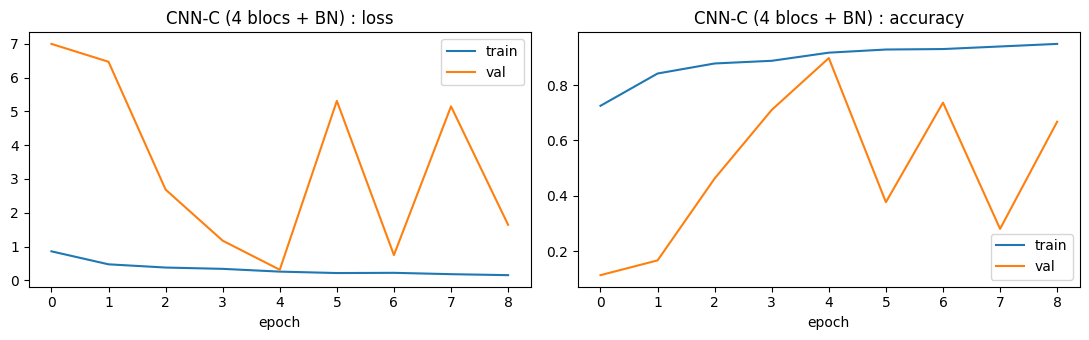

In [12]:
for name in CONFIGS:
    plot_history(hist[name], name)

In [13]:
rows = []
for name, m in cnn.items():
    h = hist[name]; b = int(np.argmin(h["val_loss"]))
    rows.append({"variante": name, "paramètres": m.count_params(), "epochs": len(h["loss"]),
                 "acc train": h["accuracy"][b], "acc val": h["val_accuracy"][b],
                 "écart train-val": h["accuracy"][b] - h["val_accuracy"][b],
                 "rappel macro val (PV)": macro_recall(m, pv_val, ds_pv_val)})
rows.append({"variante": "MLP (baseline)", "paramètres": mlp.count_params(), "epochs": len(h_mlp["loss"]),
             "acc train": h_mlp["accuracy"][int(np.argmin(h_mlp["val_loss"]))],
             "acc val": h_mlp["val_accuracy"][int(np.argmin(h_mlp["val_loss"]))],
             "écart train-val": h_mlp["accuracy"][int(np.argmin(h_mlp["val_loss"]))] - h_mlp["val_accuracy"][int(np.argmin(h_mlp["val_loss"]))],
             "rappel macro val (PV)": macro_recall(mlp, pv_val, ds_pv_val)})
comp = pd.DataFrame(rows).set_index("variante")
display(comp.round(3))

for v, r in comp.iterrows():
    print(f"{v} : écart train-val = {r['écart train-val']:.3f} -> "
          + ("surapprentissage net" if r["écart train-val"] > 0.05 else "pas de surapprentissage marqué"))

best_name = comp.loc[list(CONFIGS), "rappel macro val (PV)"].idxmax()
BEST_CFG = CONFIGS[best_name]
print("\nMeilleure variante (rappel macro en validation PlantVillage) :", best_name)

,paramètres,epochs,acc train,acc val,écart train-val,rappel macro val (PV)
variante,,,,,,
CNN-A (3 blocs + BN),95081,12,0.883,0.861,0.022,0.835
"CNN-B (3 blocs, sans BN)",94409,25,0.880,0.919,-0.040,0.913
CNN-C (4 blocs + BN),392169,9,0.917,0.897,0.020,0.883
MLP (baseline),3673097,14,0.519,0.658,-0.138,0.601


CNN-A (3 blocs + BN) : écart train-val = 0.022 -> pas de surapprentissage marqué
CNN-B (3 blocs, sans BN) : écart train-val = -0.040 -> pas de surapprentissage marqué
CNN-C (4 blocs + BN) : écart train-val = 0.020 -> pas de surapprentissage marqué
MLP (baseline) : écart train-val = -0.138 -> pas de surapprentissage marqué

Meilleure variante (rappel macro en validation PlantVillage) : CNN-B (3 blocs, sans BN)


**Analyse du surapprentissage (d'après les courbes et le tableau ci-dessus) :**
- **Écart entre les courbes train et validation :** aucune des trois variantes ne montre de surapprentissage marqué. L'écart train − validation, mesuré à l'epoch retenue, est de +0,022 (A), −0,040 (B) et +0,020 (C). L'écart négatif de B s'explique par le dropout (0,4), actif pendant l'entraînement et pas en validation. L'arrêt anticipé a stoppé A à l'epoch 12 et C à l'epoch 9. B a utilisé les 25 epochs et progressait encore. La validation de A est très instable au début (accuracy de validation de 0,13 aux epochs 1 et 2), probablement parce que les statistiques de la batch normalization sont encore mal estimées en début d'entraînement.
- **Effet de la batch normalization (A vs B) :** la variante sans BN (B) est meilleure en validation (accuracy 0,919 contre 0,861 ; rappel macro 0,913 contre 0,835). La BN accélère le début de l'entraînement (accuracy d'entraînement de 0,63 contre 0,34 à l'epoch 1), mais la validation reste instable et l'arrêt anticipé se déclenche plus tôt. Dans ce montage, la BN n'améliore donc pas la généralisation. B est retenue pour la suite.
- **Effet de la profondeur (A vs C) :** passer de 3 à 4 blocs avec BN améliore la validation (accuracy 0,897 contre 0,861 ; rappel macro 0,883 contre 0,835), au prix de 4 fois plus de paramètres (392 169 contre 95 081). L'écart train − validation reste comparable (0,020 contre 0,022), donc la profondeur supplémentaire n'ajoute pas de surapprentissage. B (3 blocs, sans BN) reste cependant meilleure que C.
- **Apport du CNN par rapport au MLP :** le MLP atteint 0,658 d'accuracy et 0,601 de rappel macro en validation, contre 0,919 et 0,913 pour CNN-B, soit environ 31 points de rappel macro en plus, avec 39 fois moins de paramètres (94 409 contre 3 673 097). Le MLP sous-apprend (accuracy d'entraînement de 0,52) : aplatir l'image détruit la structure spatiale, et la taille du modèle ne compense pas. Cela justifie l'usage d'un CNN.
- **Limite :** chaque variante n'a été entraînée qu'une fois (une seule graine), donc les écarts de quelques points entre variantes sont à interpréter avec prudence.

## Étape 4 — Test de robustesse
### 4.1 Entraîner sur PlantVillage, tester sur PlantDoc : mesure de la chute de performance

In [14]:
NAME_BASE = "CNN PV seul (baseline)"
baseline = cnn[best_name]
evaluate(NAME_BASE, baseline)

r = RESULTS[NAME_BASE]
chute = pd.DataFrame({"Labo": [r["Labo rappel macro"], r["Labo F1 macro"]],
                      "Terrain": [r["Terrain rappel macro"], r["Terrain F1 macro"]]}, index=["rappel macro", "F1 macro"])
chute["chute (points)"] = (chute["Labo"] - chute["Terrain"]) * 100
print("\nChute de performance labo -> terrain")
display(chute.round(3))


CNN PV seul (baseline) — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.868,0.969,0.916
Early_blight,0.730,0.847,0.784
Late_blight,0.909,0.804,0.853
Leaf_Mold,0.843,0.937,0.887
Septoria_leaf_spot,0.979,0.891,0.933
Spider_mites,0.974,0.908,0.940
Mosaic_virus,0.889,1.000,0.941
Yellow_Leaf_Curl_Virus,0.972,0.956,0.964
Healthy,0.979,0.992,0.985



CNN PV seul (baseline) — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.286,0.074,0.118
Early_blight,0.098,0.273,0.145
Late_blight,0.095,0.071,0.082
Leaf_Mold,0.250,0.043,0.074
Septoria_leaf_spot,0.343,0.316,0.329
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.000,0.000,0.000
Yellow_Leaf_Curl_Virus,0.128,0.316,0.182
Healthy,0.167,0.062,0.091



Chute de performance labo -> terrain


,Labo,Terrain,chute (points)
rappel macro,0.923,0.128,79.417
F1 macro,0.912,0.113,79.828


### 4.2 Stratégies pour réduire l'écart
**(a) Data augmentation** : rotations, luminosité, recadrage, changement de fond. Entraînement sur PlantVillage uniquement.

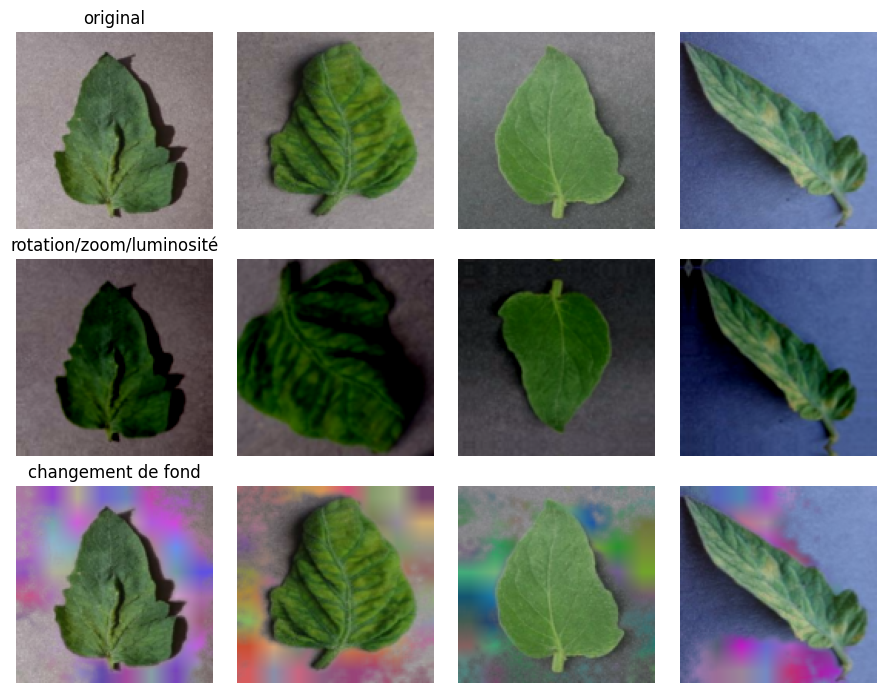

Epoch 1/40
184/184 - 66s - 361ms/step - accuracy: 0.2553 - loss: 2.1072 - val_accuracy: 0.3428 - val_loss: 1.8338
Epoch 2/40
184/184 - 42s - 229ms/step - accuracy: 0.3444 - loss: 1.9264 - val_accuracy: 0.3639 - val_loss: 1.8123
Epoch 3/40
184/184 - 42s - 227ms/step - accuracy: 0.4115 - loss: 1.7593 - val_accuracy: 0.5533 - val_loss: 1.3048
Epoch 4/40
184/184 - 41s - 225ms/step - accuracy: 0.4521 - loss: 1.6512 - val_accuracy: 0.6091 - val_loss: 1.2285
Epoch 5/40
184/184 - 42s - 228ms/step - accuracy: 0.4944 - loss: 1.5286 - val_accuracy: 0.5227 - val_loss: 1.3128
Epoch 6/40
184/184 - 82s - 447ms/step - accuracy: 0.5104 - loss: 1.4682 - val_accuracy: 0.5677 - val_loss: 1.1745
Epoch 7/40
184/184 - 42s - 229ms/step - accuracy: 0.5418 - loss: 1.3690 - val_accuracy: 0.5836 - val_loss: 1.1734
Epoch 8/40
184/184 - 82s - 444ms/step - accuracy: 0.5637 - loss: 1.3259 - val_accuracy: 0.6509 - val_loss: 0.9942
Epoch 9/40
184/184 - 82s - 447ms/step - accuracy: 0.5819 - loss: 1.2852 - val_accuracy: 

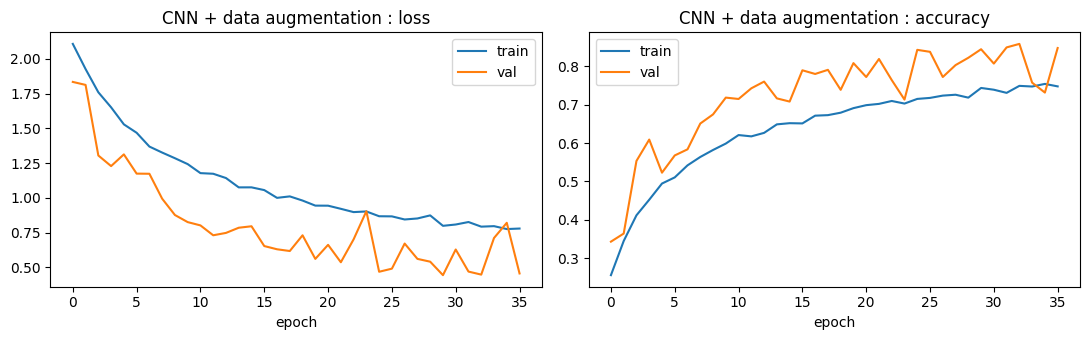


CNN + data augmentation — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.866,0.875,0.871
Early_blight,0.508,0.887,0.646
Late_blight,0.859,0.747,0.799
Leaf_Mold,0.848,0.783,0.815
Septoria_leaf_spot,0.988,0.639,0.776
Spider_mites,0.789,0.880,0.832
Mosaic_virus,0.609,1.000,0.757
Yellow_Leaf_Curl_Virus,0.969,0.900,0.934
Healthy,0.922,0.996,0.958



CNN + data augmentation — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.200,0.037,0.062
Early_blight,0.129,0.409,0.196
Late_blight,0.182,0.071,0.103
Leaf_Mold,0.500,0.043,0.080
Septoria_leaf_spot,0.526,0.263,0.351
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.200,0.462,0.279
Yellow_Leaf_Curl_Virus,0.200,0.421,0.271
Healthy,0.000,0.000,0.000


{'Labo rappel macro': np.float64(0.8564146316869053),
 'Labo F1 macro': np.float64(0.8207235601513978),
 'Terrain rappel macro': np.float64(0.18964264069781486),
 'Terrain F1 macro': np.float64(0.1490944086199365)}

In [15]:
NAME_AUG = "CNN + data augmentation"
x = next(iter(ds_pv_val))[0][:4]
fig, ax = plt.subplots(3, 4, figsize=(9, 7))
aug_layer = augmentation_block()
for j in range(4):
    ax[0, j].imshow(x[j]); ax[1, j].imshow(np.clip(aug_layer(x[j:j+1], training=True)[0], 0, 1))
    ax[2, j].imshow(random_background(x[j], p=1.0))
    for i in range(3):
        ax[i, j].axis("off")
ax[0, 0].set_title("original"); ax[1, 0].set_title("rotation/zoom/luminosité"); ax[2, 0].set_title("changement de fond")
plt.tight_layout(); plt.show()

keras.utils.set_random_seed(SEED)
m_aug = build_cnn(**BEST_CFG, aug=True)
h_aug = train(m_aug, make_ds(pv_train, True, bg=True), ds_pv_val, cw_pv, epochs=40, patience=6)
plot_history(h_aug, NAME_AUG)
evaluate(NAME_AUG, m_aug)

**(b) Ré-entraînement du CNN sur une partie de PlantDoc** : on repart du CNN entraîné sur PlantVillage et on l'ajuste sur PlantDoc (train), avec un learning rate réduit. La validation et le test PlantDoc restent séparés.

Epoch 1/30
7/7 - 11s - 2s/step - accuracy: 0.2014 - loss: 16.6527 - val_accuracy: 0.1857 - val_loss: 13.9634
Epoch 2/30
7/7 - 0s - 57ms/step - accuracy: 0.1942 - loss: 15.1471 - val_accuracy: 0.1786 - val_loss: 13.1713
Epoch 3/30
7/7 - 0s - 47ms/step - accuracy: 0.1487 - loss: 13.8849 - val_accuracy: 0.1571 - val_loss: 12.2761
Epoch 4/30
7/7 - 0s - 50ms/step - accuracy: 0.1823 - loss: 15.1407 - val_accuracy: 0.1429 - val_loss: 11.4545
Epoch 5/30
7/7 - 0s - 51ms/step - accuracy: 0.1559 - loss: 13.9340 - val_accuracy: 0.1357 - val_loss: 10.8037
Epoch 6/30
7/7 - 0s - 48ms/step - accuracy: 0.1607 - loss: 12.6770 - val_accuracy: 0.1429 - val_loss: 10.2002
Epoch 7/30
7/7 - 0s - 49ms/step - accuracy: 0.1703 - loss: 10.1137 - val_accuracy: 0.1429 - val_loss: 9.7569
Epoch 8/30
7/7 - 0s - 50ms/step - accuracy: 0.1847 - loss: 9.7233 - val_accuracy: 0.1357 - val_loss: 9.3823
Epoch 9/30
7/7 - 1s - 88ms/step - accuracy: 0.1823 - loss: 9.8283 - val_accuracy: 0.1214 - val_loss: 9.0027
Epoch 10/30
7/7 

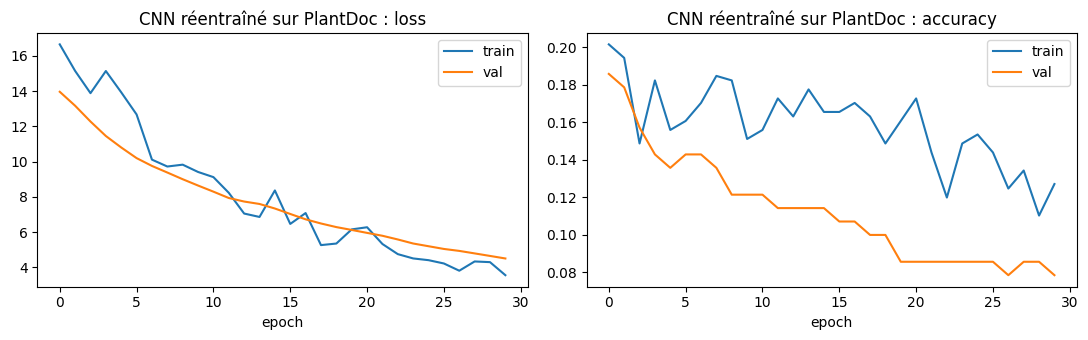


CNN réentraîné sur PlantDoc — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.238,0.997,0.384
Early_blight,1.000,0.040,0.077
Late_blight,0.767,0.081,0.146
Leaf_Mold,0.366,0.371,0.368
Septoria_leaf_spot,0.000,0.000,0.000
Spider_mites,0.245,0.359,0.291
Mosaic_virus,0.120,0.304,0.172
Yellow_Leaf_Curl_Virus,1.000,0.004,0.007
Healthy,0.012,0.025,0.017



CNN réentraîné sur PlantDoc — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.148,0.148,0.148
Early_blight,0.200,0.045,0.074
Late_blight,0.000,0.000,0.000
Leaf_Mold,0.200,0.130,0.158
Septoria_leaf_spot,0.500,0.105,0.174
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.136,0.462,0.211
Yellow_Leaf_Curl_Virus,0.143,0.158,0.150
Healthy,0.000,0.000,0.000


{'Labo rappel macro': np.float64(0.242141657968612),
 'Labo F1 macro': np.float64(0.16248424569149023),
 'Terrain rappel macro': np.float64(0.11652598138741031),
 'Terrain F1 macro': np.float64(0.10161736870356244)}

In [16]:
NAME_FT = "CNN réentraîné sur PlantDoc"
keras.utils.set_random_seed(SEED)
m_ft = build_cnn(**BEST_CFG, aug=True)
copy_weights(baseline, m_ft)
h_ft = train(m_ft, ds_pd_train, ds_pd_val, cw(pd_train.y), epochs=30, lr=1e-4, patience=5)
plot_history(h_ft, NAME_FT)
evaluate(NAME_FT, m_ft)

**(c) Entraînement mixte PlantVillage + PlantDoc** : les images PlantDoc d'entraînement sont répétées pour équilibrer les deux sources ; augmentation active ; validation sur PlantVillage val + PlantDoc val.

PlantDoc répété 7 fois | images d'entraînement mixtes : 14637
Epoch 1/40
229/229 - 118s - 515ms/step - accuracy: 0.2317 - loss: 2.1177 - val_accuracy: 0.0283 - val_loss: 2.3739
Epoch 2/40
229/229 - 52s - 227ms/step - accuracy: 0.2878 - loss: 2.0323 - val_accuracy: 0.0551 - val_loss: 2.2430
Epoch 3/40
229/229 - 52s - 227ms/step - accuracy: 0.3304 - loss: 1.9164 - val_accuracy: 0.1576 - val_loss: 2.1594
Epoch 4/40
229/229 - 52s - 227ms/step - accuracy: 0.3784 - loss: 1.8288 - val_accuracy: 0.2956 - val_loss: 1.8251
Epoch 5/40
229/229 - 52s - 228ms/step - accuracy: 0.4130 - loss: 1.7290 - val_accuracy: 0.4717 - val_loss: 1.7570
Epoch 6/40
229/229 - 82s - 359ms/step - accuracy: 0.4282 - loss: 1.6840 - val_accuracy: 0.4593 - val_loss: 1.7072
Epoch 7/40
229/229 - 82s - 359ms/step - accuracy: 0.4501 - loss: 1.6238 - val_accuracy: 0.5102 - val_loss: 1.5349
Epoch 8/40
229/229 - 81s - 353ms/step - accuracy: 0.4721 - loss: 1.5663 - val_accuracy: 0.5577 - val_loss: 1.5150
Epoch 9/40
229/229 - 52s 

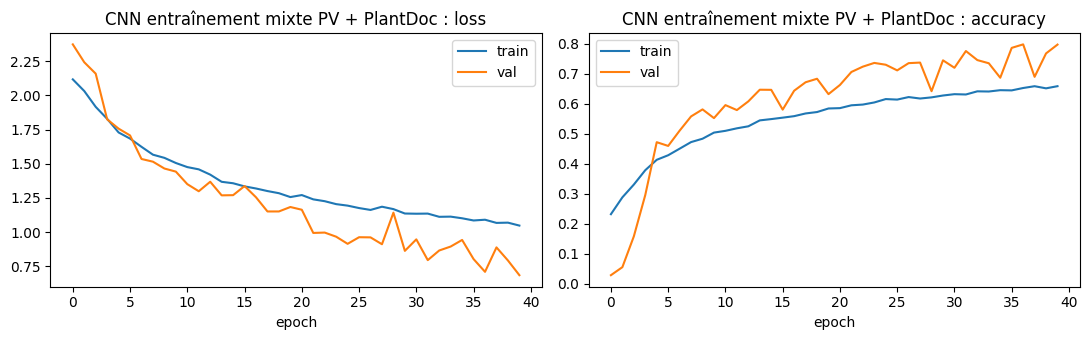


CNN entraînement mixte PV + PlantDoc — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.888,0.893,0.891
Early_blight,0.733,0.640,0.683
Late_blight,0.870,0.565,0.685
Leaf_Mold,0.519,0.846,0.644
Septoria_leaf_spot,0.951,0.511,0.665
Spider_mites,0.655,0.976,0.784
Mosaic_virus,0.712,0.929,0.806
Yellow_Leaf_Curl_Virus,0.960,0.929,0.944
Healthy,0.858,0.987,0.918



CNN entraînement mixte PV + PlantDoc — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.000,0.000,0.000
Early_blight,0.172,0.227,0.196
Late_blight,0.182,0.071,0.103
Leaf_Mold,0.189,0.435,0.263
Septoria_leaf_spot,0.625,0.263,0.370
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.071,0.308,0.116
Yellow_Leaf_Curl_Virus,0.400,0.105,0.167
Healthy,0.375,0.188,0.250


{'Labo rappel macro': np.float64(0.8085475257711613),
 'Labo F1 macro': np.float64(0.7800226234080879),
 'Terrain rappel macro': np.float64(0.17745525196898196),
 'Terrain F1 macro': np.float64(0.16275327718844868)}

In [17]:
NAME_MIX = "CNN entraînement mixte PV + PlantDoc"
k = max(1, len(pv_train) // (4 * len(pd_train)))
mix_train = pd.concat([pv_train] + [pd_train] * k, ignore_index=True)
mix_val = pd.concat([pv_val, pd_val], ignore_index=True)
print(f"PlantDoc répété {k} fois | images d'entraînement mixtes : {len(mix_train)}")

keras.utils.set_random_seed(SEED)
m_mix = build_cnn(**BEST_CFG, aug=True)
h_mix = train(m_mix, make_ds(mix_train, True, bg=True), make_ds(mix_val), cw(mix_train.y), epochs=40, patience=6)
plot_history(h_mix, NAME_MIX)
evaluate(NAME_MIX, m_mix)

### 4.3 Comparaison des stratégies (laboratoire ET terrain)
Le modèle final est choisi sur le **rappel macro en validation PlantDoc** (jamais sur le test).

,Labo rappel macro,Labo F1 macro,Terrain rappel macro,Terrain F1 macro,chute rappel macro (points)
CNN PV seul (baseline),0.923,0.912,0.128,0.113,79.417
CNN + data augmentation,0.856,0.821,0.190,0.149,66.677
CNN réentraîné sur PlantDoc,0.242,0.162,0.117,0.102,12.562
CNN entraînement mixte PV + PlantDoc,0.809,0.780,0.177,0.163,63.109


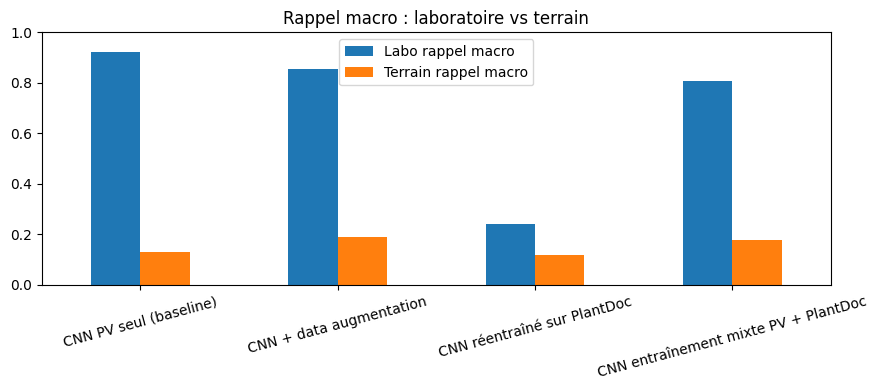

Rappel macro en validation PlantDoc : {'CNN PV seul (baseline)': 0.158, 'CNN + data augmentation': 0.211, 'CNN réentraîné sur PlantDoc': 0.087, 'CNN entraînement mixte PV + PlantDoc': 0.252}
Modèle final retenu : CNN entraînement mixte PV + PlantDoc


In [18]:
res = pd.DataFrame(RESULTS).T.loc[[NAME_BASE, NAME_AUG, NAME_FT, NAME_MIX]]
res["chute rappel macro (points)"] = (res["Labo rappel macro"] - res["Terrain rappel macro"]) * 100
display(res.round(3))

res[["Labo rappel macro", "Terrain rappel macro"]].plot.bar(figsize=(9, 4), ylim=(0, 1), rot=15,
                                                           title="Rappel macro : laboratoire vs terrain")
plt.tight_layout(); plt.show()

cands = {NAME_BASE: baseline, NAME_AUG: m_aug, NAME_FT: m_ft, NAME_MIX: m_mix}
scores = {n: macro_recall(m, pd_val, ds_pd_val) for n, m in cands.items()}
final_name = max(scores, key=scores.get); final_model = cands[final_name]
print("Rappel macro en validation PlantDoc :", {k: round(v, 3) for k, v in scores.items()})
print("Modèle final retenu :", final_name)

## Étape 5 — Analyse des erreurs et explicabilité
Modèle analysé : le modèle final retenu en 4.3.
### 5.1 Matrice de confusion et rappel par classe

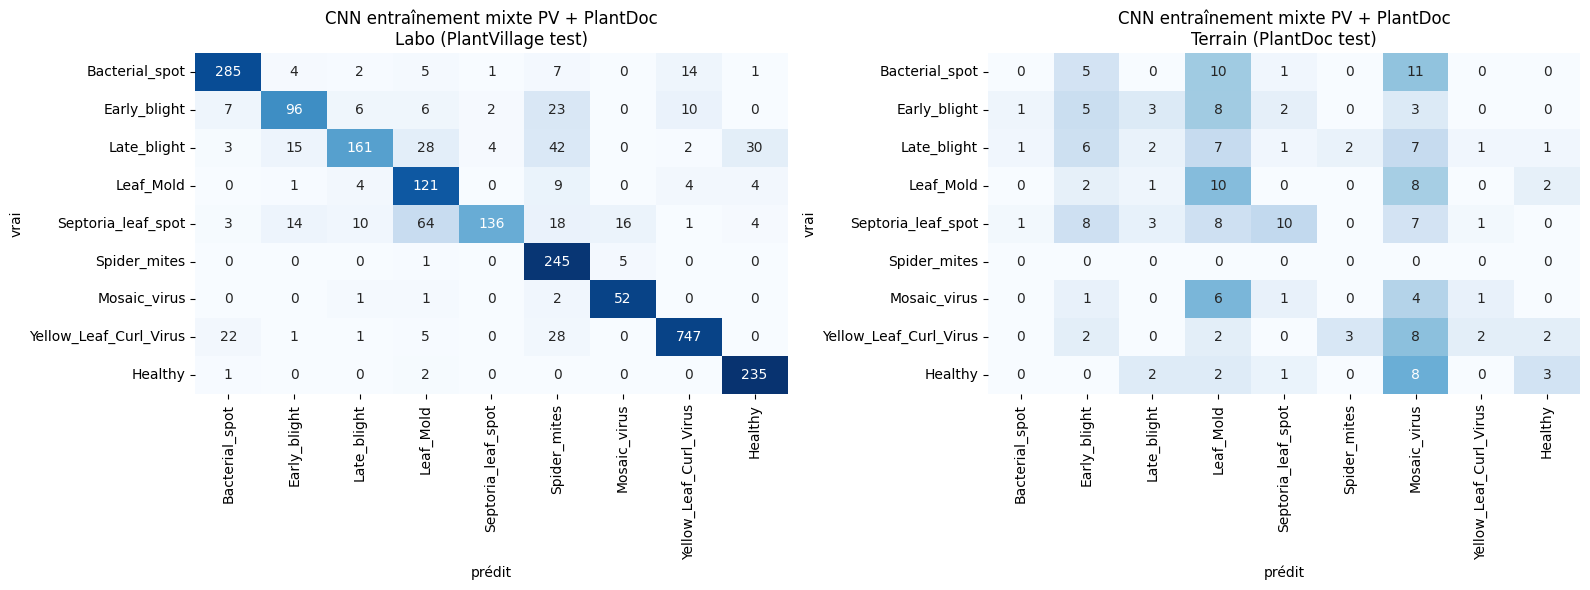


CNN entraînement mixte PV + PlantDoc — Labo (test)


,précision,rappel,F1
Bacterial_spot,0.888,0.893,0.891
Early_blight,0.733,0.640,0.683
Late_blight,0.870,0.565,0.685
Leaf_Mold,0.519,0.846,0.644
Septoria_leaf_spot,0.951,0.511,0.665
Spider_mites,0.655,0.976,0.784
Mosaic_virus,0.712,0.929,0.806
Yellow_Leaf_Curl_Virus,0.960,0.929,0.944
Healthy,0.858,0.987,0.918



CNN entraînement mixte PV + PlantDoc — Terrain (test)


,précision,rappel,F1
Bacterial_spot,0.000,0.000,0.000
Early_blight,0.172,0.227,0.196
Late_blight,0.182,0.071,0.103
Leaf_Mold,0.189,0.435,0.263
Septoria_leaf_spot,0.625,0.263,0.370
Spider_mites,0.000,0.000,0.000
Mosaic_virus,0.071,0.308,0.116
Yellow_Leaf_Curl_Virus,0.400,0.105,0.167
Healthy,0.375,0.188,0.250


{'Labo rappel macro': np.float64(0.8085475257711613),
 'Labo F1 macro': np.float64(0.7800226234080879),
 'Terrain rappel macro': np.float64(0.17745525196898196),
 'Terrain F1 macro': np.float64(0.16275327718844868)}

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, (dom, d, ds) in zip(ax, [("Labo (PlantVillage test)", pv_test, ds_pv_test), ("Terrain (PlantDoc test)", pd_test, ds_pd_test)]):
    y, yp, _ = predict(final_model, d, ds)
    cm = confusion_matrix(y, yp, labels=range(N))
    sns.heatmap(cm / cm.sum(1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(f"{final_name}\n{dom}"); a.set_xlabel("prédit"); a.set_ylabel("vrai")
plt.tight_layout(); plt.show()

evaluate(final_name, final_model, show=True)

### 5.2 Exemples mal classés
Erreurs de PlantDoc (test) classées de la plus confiante à la moins confiante. La luminosité moyenne de l'image est affichée pour aider à formuler les hypothèses.

150 erreurs sur 186 images PlantDoc (test)



,nombre d'erreurs
Bacterial_spot -> Mosaic_virus,11
Bacterial_spot -> Leaf_Mold,10
Early_blight -> Leaf_Mold,8
Septoria_leaf_spot -> Early_blight,8
Leaf_Mold -> Mosaic_virus,8
Septoria_leaf_spot -> Leaf_Mold,8
Healthy -> Mosaic_virus,8
Yellow_Leaf_Curl_Virus -> Mosaic_virus,8


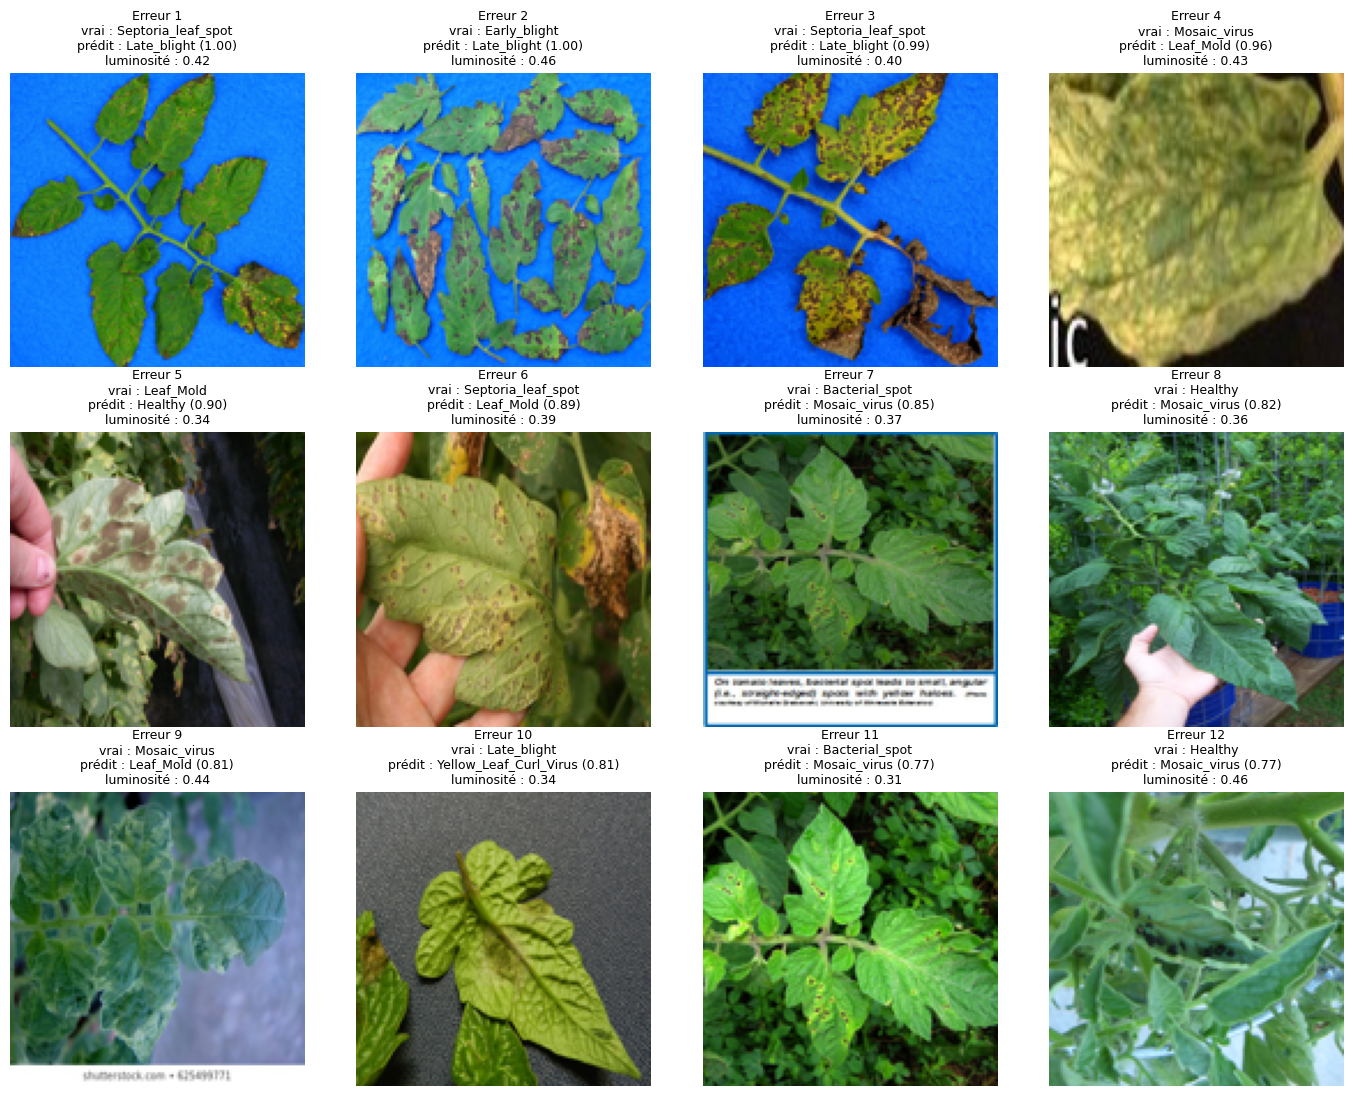

In [20]:
def load_img(path):
    return np.asarray(Image.open(path).convert("RGB").resize((IMG, IMG)), dtype="float32") / 255.0

y, yp, pr = predict(final_model, pd_test, ds_pd_test)
err = np.where(y != yp)[0]
print(f"{len(err)} erreurs sur {len(y)} images PlantDoc (test)\n")
pairs = pd.Series([f"{CLASSES[a]} -> {CLASSES[b]}" for a, b in zip(y[err], yp[err])]).value_counts().head(8)
display(pairs.rename("nombre d'erreurs").to_frame())

sel = err[np.argsort(-pr[err].max(1))][:12]
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for n_, (a, i) in enumerate(zip(axes.ravel(), sel), 1):
    img = load_img(pd_test.path.iloc[i])
    a.imshow(img); a.axis("off")
    a.set_title(f"Erreur {n_}\nvrai : {CLASSES[y[i]]}\nprédit : {CLASSES[yp[i]]} ({pr[i].max():.2f})\nluminosité : {img.mean():.2f}", fontsize=9)
plt.tight_layout(); plt.show()

**Hypothèse sur la cause de chaque erreur** (observation visuelle des 12 erreurs les plus confiantes du modèle final sur PlantDoc test ; ces hypothèses ne sont pas testées par une expérience) :

Sur 186 images PlantDoc de test, le modèle final se trompe 150 fois. Les confusions les plus fréquentes sont Bacterial_spot → Mosaic_virus (11), Bacterial_spot → Leaf_Mold (10) et plusieurs classes → Mosaic_virus ou Leaf_Mold, qui servent de classes « refuge ».

| Erreur | Vraie classe → classe prédite | Hypothèse |
|---|---|---|
| 1 | Septoria_leaf_spot → Late_blight (1,00) | Fond bleu saturé, absent des images d'entraînement. Le modèle réagit au fond et aux contours des feuilles, pas aux petites lésions de la septoriose. |
| 2 | Early_blight → Late_blight (1,00) | Même fond bleu, et plusieurs feuilles petites sur une même image. Les lésions brunes de l'alternariose ressemblent à celles du mildiou à cette résolution (128 px). |
| 3 | Septoria_leaf_spot → Late_blight (0,99) | Même fond bleu, feuilles jaunies et partiellement desséchées : la nécrose avancée masque la forme des taches de septoriose. |
| 4 | Mosaic_virus → Leaf_Mold (0,96) | Zoom extrême sur une feuille floue et jaunâtre, sans contexte (un morceau de texte est visible). Le jaunissement diffus de la mosaïque ressemble à celui de la moisissure. |
| 5 | Leaf_Mold → Healthy (0,90) | Feuille tenue à la main, taches grisâtres de faible contraste sur un limbe pâle, fond sombre : les lésions sont peu visibles. |
| 6 | Septoria_leaf_spot → Leaf_Mold (0,89) | Feuille tenue à la main, jaunie, avec de petites taches : le jaunissement général est associé à la moisissure. |
| 7 | Bacterial_spot → Mosaic_virus (0,85) | Image de manuel avec légende et cadre, lésions très petites : elles disparaissent après réduction à 128 px, et le fond de végétation domine. |
| 8 | Healthy → Mosaic_virus (0,82) | Plan large d'une plante, feuille tenue à la main, sans lésion. Le relief et les contrastes clair/foncé de la feuille sont pris pour une mosaïque. |
| 9 | Mosaic_virus → Leaf_Mold (0,81) | Image de banque d'images avec filigrane, teinte bleutée et faible qualité, qui perturbent les couleurs sur lesquelles le modèle s'appuie. |
| 10 | Late_blight → Yellow_Leaf_Curl_Virus (0,81) | Feuille froissée, très jaune-vert, sur fond gris foncé : sa forme et sa couleur évoquent le virus des feuilles jaunes en cuillère, et les lésions du mildiou sont peu visibles. |
| 11 | Bacterial_spot → Mosaic_virus (0,77) | Quelques taches minuscules sur fond de végétation dense, perdues à 128 px, avec un limbe éclairci vert clair proche de la mosaïque. |
| 12 | Healthy → Mosaic_virus (0,77) | Gros plan flou de feuilles qui se chevauchent, avec ombres et relief, sans lésion : les contrastes irréguliers sont interprétés comme une mosaïque. |

**Schémas communs :** fonds hors distribution (bleu saturé), mains et plans larges, lésions trop petites pour la résolution utilisée, images de faible qualité, et classes aux symptômes proches (alternariose / mildiou, mosaïque / moisissure). La plupart de ces conditions n'existent pas dans PlantVillage.

### 5.3 Grad-CAM
Vérification que le modèle regarde la lésion de la feuille et non le fond. Lignes : PlantDoc bien classées, PlantDoc mal classées, PlantVillage.

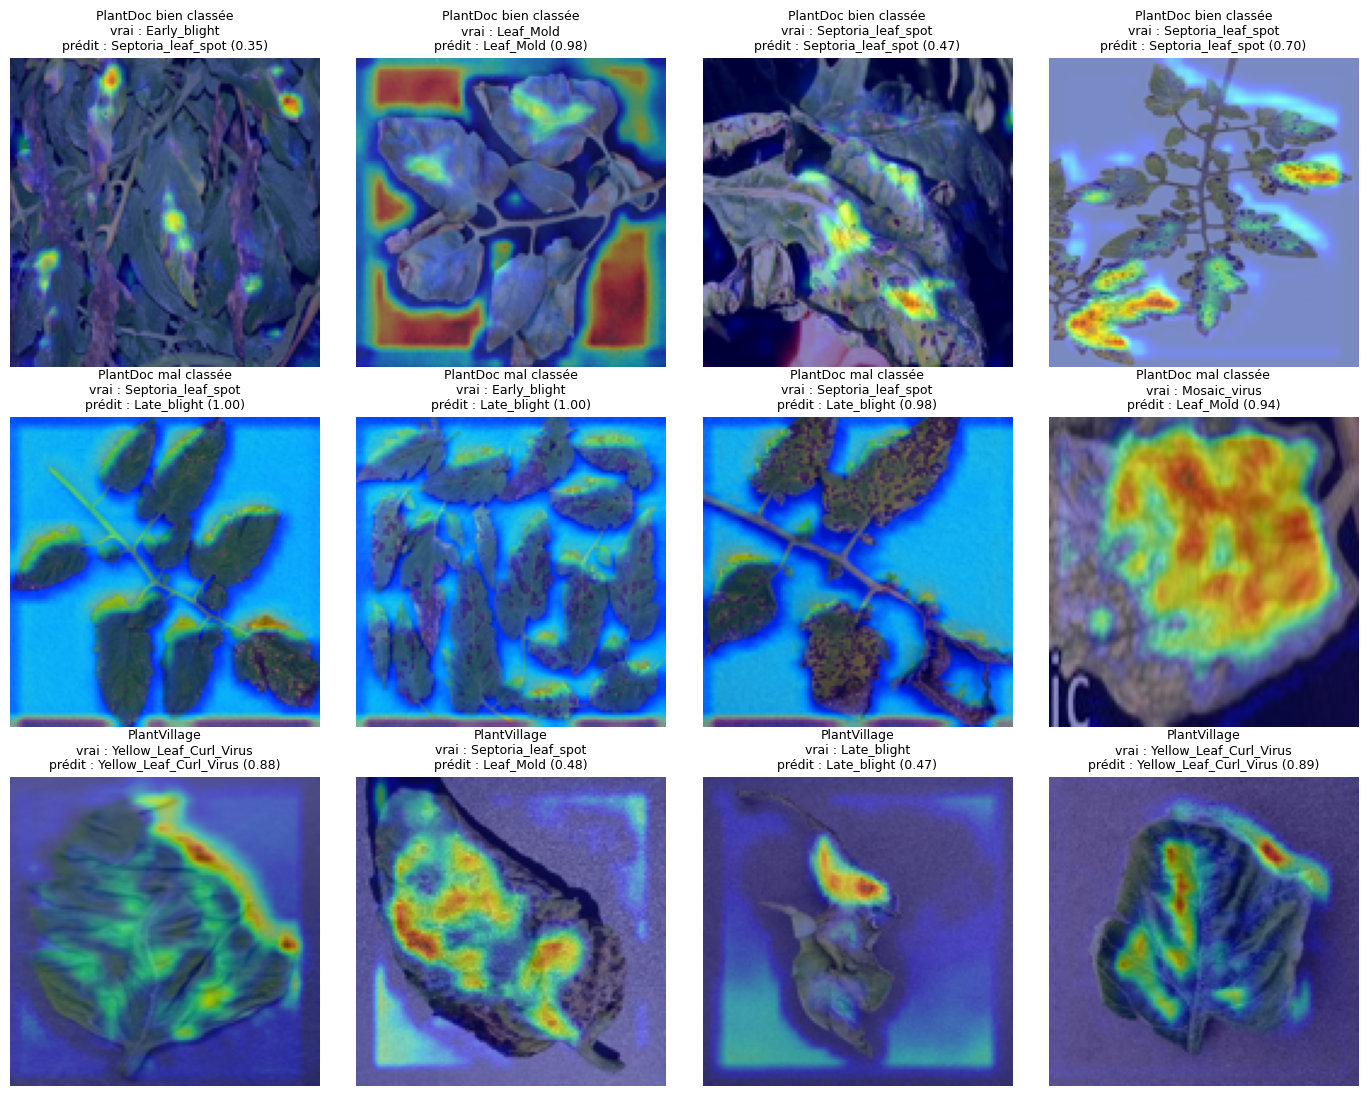

In [21]:
def gradcam(model, img):
    gm = keras.Model(model.inputs, [model.get_layer("last_conv").output, model.output])
    with tf.GradientTape() as tape:
        conv, preds = gm(img[None], training=False)
        cls = tf.argmax(preds[0])
        score = preds[:, cls]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.nn.relu(tf.reduce_sum(conv * w[:, None, None, :], axis=-1)[0])
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]
    return cam, int(cls), float(preds[0, cls])

rng = np.random.RandomState(SEED)
ok_idx = rng.choice(np.where(y == yp)[0], 4, replace=False)
pv_idx = rng.choice(len(pv_test), 4, replace=False)
groups = [("PlantDoc bien classée", pd_test, ok_idx), ("PlantDoc mal classée", pd_test, sel[:4]), ("PlantVillage", pv_test, pv_idx)]

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for r_, (title, d, idx) in enumerate(groups):
    for c_, i in enumerate(idx):
        img = load_img(d.path.iloc[i])
        cam, pred, conf = gradcam(final_model, img)
        a = axes[r_, c_]; a.imshow(img); a.imshow(cam, cmap="jet", alpha=0.45); a.axis("off")
        a.set_title(f"{title}\nvrai : {CLASSES[d.y.iloc[i]]}\nprédit : {CLASSES[pred]} ({conf:.2f})", fontsize=9)
plt.tight_layout(); plt.show()

**Conclusion Grad-CAM (d'après les cartes ci-dessus) :**
- **PlantDoc bien classées :** pour 3 images sur 4, la carte se concentre sur des zones de lésion (taches de septoriose, zones malades). Pour l'image de Leaf_Mold classée avec 0,98 de confiance, les zones les plus chaudes sont les coins et les bords de l'image, donc le fond : la bonne réponse peut venir d'un mauvais indice. Pour la première image, le Grad-CAM affiche une classe différente (Septoria_leaf_spot, confiance 0,35) de celle de l'évaluation. Le Grad-CAM recharge l'image avec un redimensionnement légèrement différent, ce qui suffit à faire basculer une prédiction peu confiante.
- **PlantDoc mal classées :** pour les trois erreurs sur fond bleu, la carte met en évidence le contour des feuilles et le fond bleu plutôt que les lésions, avec une confiance de 0,98 à 1,00 pour Late_blight. Le modèle ne regarde donc pas la lésion dans ces cas. Pour la mosaïque classée Leaf_Mold, l'activation couvre toute la feuille sans cibler de symptôme précis.
- **PlantVillage :** l'attention se porte surtout sur la feuille (lésions, bord jaunâtre, nervures), avec parfois une activation sur les bords du cadre uniforme. Cela correspond à un comportement plus attendu qu'en conditions réelles. Une erreur (Septoria prédit Leaf_Mold, confiance 0,48) montre toutefois que même en laboratoire la décision peut être peu assurée.
- **Lien avec les erreurs :** le modèle ne vérifie pas de façon fiable qu'il regarde la lésion, surtout sur fond non vu à l'entraînement. Les erreurs sur PlantDoc sont donc en partie dues à l'usage du fond et du contour comme indices. Les cartes ci-dessus ne portent que sur 12 images : elles illustrent ce comportement sans le quantifier.